# Modelo VAEP Atômico Enriquecido com Features de Tracking

Este notebook implementa e avalia um modelo de valoração de ações no futebol (VAEP - Valuing Actions by Estimating Probabilities) com uma abordagem híbrida, combinando dados de evento (SPADL) com features extraídas de dados de tracking.

## Fluxo de Trabalho Experimental

O processo é dividido em **três grandes etapas** para permitir uma comparação justa e clara do impacto das features de tracking:

### 1. Modelo VAEP Baseline
- **Objetivo:** Estabelecer uma linha de base de performance.
- **Metodologia:** Um modelo VAEP atômico padrão é treinado utilizando exclusivamente features derivadas dos dados de evento SPADL. Este modelo serve como nosso ponto de referência.

### 2. Classificador de Sucesso Enriquecido
- **Objetivo:** Prever a probabilidade de uma ação ser bem-sucedida, utilizando um contexto tático que não está presente nos dados de evento.
- **Metodologia:**
    - Extraímos a feature **`compactação defensiva`** dos dados de tracking para cada ação.
    - Um classificador (XGBoost) é treinado para prever o sucesso de uma ação (`result_name`). As suas features de entrada são as features SPADL padrão **MAIS** a feature de `compactação defensiva`.
    - A performance deste classificador é avaliada para garantir que ele aprendeu padrões significativos.

### 3. Modelo VAEP Final (Híbrido)
- **Objetivo:** Avaliar o impacto de um classificador de sucesso "mais inteligente" na performance final do VAEP.
- **Metodologia:**
    - O classificador treinado na Etapa 2 é usado para gerar uma nova feature: `success_score` (a probabilidade de sucesso da ação).
    - Um novo modelo VAEP é treinado. Suas features de entrada são as features SPADL padrão **MAIS** a feature `success_score`.
    - A performance deste modelo final é comparada com o VAEP Baseline para quantificar o ganho obtido ao incorporar o contexto dos dados de tracking de forma indireta (através do classificador).

Ao final, o notebook gera os valores de VAEP para os jogadores e plota gráficos de diagnóstico detalhados para os modelos finais.

In [44]:
import pandas as pd
import numpy as np
from tqdm import tqdm
from xgboost import XGBClassifier
from sklearn.metrics import brier_score_loss
from socceraction.vaep import features as ft
from socceraction.vaep import labels as lab
from socceraction.vaep import formula as fm
from socceraction.atomic.spadl import convert_to_atomic
from sklearn.model_selection import GroupShuffleSplit, train_test_split
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve, roc_auc_score
import seaborn as sns
import os

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_parquet('spadl_events/spadl.parquet')
df

,game_id,period_id,team_id,player_id,start_x,start_y,end_x,end_y,original_event_id,time_seconds,type_id,type_name,result_id,result_name,bodypart_id,bodypart_name,action_id
0,13335,1,5,15620,0.503105,0.504544,0.326924,0.436265,12926009.0,153.887,0,pass,1,success,5,foot_right,0
1,13335,1,5,4696,0.329743,0.457456,0.760200,0.735603,12926647.0,156.623,0,pass,0,fail,5,foot_right,1
2,13335,1,5,14278,0.760200,0.735603,NaN,NaN,12926642.0,159.860,9,tackle,0,fail,0,foot,2
3,13335,1,11,284,0.760200,0.735603,NaN,NaN,12926642.0,159.860,9,tackle,1,success,0,foot,3
4,13335,1,5,13068,0.760200,0.735603,NaN,NaN,12926642.0,159.860,9,tackle,0,fail,0,foot,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
551573,20480,2,218,567,0.298400,0.550824,NaN,NaN,18703655.0,6430.097,9,tackle,1,success,0,foot,551573
551574,20480,2,218,567,0.296752,0.552118,0.273371,0.727029,18703656.0,6430.130,0,pass,1,success,1,head,551574
551575,20480,2,218,7252,0.280362,0.659956,0.305095,0.593382,18703661.0,6433.100,21,dribble,1,success,0,foot,551575
551576,20480,2,218,7252,0.305095,0.593382,0.118105,0.120397,18703665.0,6434.101,0,pass,1,success,5,foot_right,551576


In [4]:
## Mantendo apenas a primeira linha de cada event_id

df = df.sort_values(by='time_seconds').drop_duplicates(subset=['original_event_id'], keep = 'first')

In [5]:
df

,game_id,period_id,team_id,player_id,start_x,start_y,end_x,end_y,original_event_id,time_seconds,type_id,type_name,result_id,result_name,bodypart_id,bodypart_name,action_id
158476,13445,1,5,19642,0.495057,0.491588,0.773095,0.547353,15517588.0,0.434,0,pass,1,success,5,foot_right,158476
465196,13656,1,12,133,0.503295,0.489559,0.153314,0.619956,19747889.0,4.137,0,pass,1,success,5,foot_right,465196
417892,13623,1,3,7271,0.495448,0.501897,0.569971,0.438250,18767219.0,4.805,0,pass,1,success,5,foot_right,417892
158477,13445,1,5,6056,0.775990,0.523485,0.377086,0.230706,15522387.0,5.038,0,pass,1,success,5,foot_right,158477
285661,13533,1,4,430,0.497438,0.486235,0.685876,0.449397,16260084.0,5.272,0,pass,1,success,5,foot_right,285661
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110021,13410,2,15,536,0.872571,0.382603,NaN,NaN,14886133.0,7064.431,9,tackle,1,success,0,foot,110021
110022,13410,2,15,536,0.872571,0.382603,0.903848,0.531897,14886134.0,7064.464,0,pass,0,fail,1,head,110022
110023,13410,2,54,1973,0.903848,0.531897,0.805390,0.599574,14886140.0,7066.500,18,clearance,1,success,0,foot,110023
110025,13410,2,15,1929,0.805390,0.599574,NaN,NaN,14886145.0,7068.469,9,tackle,1,success,0,foot,110025


In [6]:
# Ordenar ações por tempo dentro de cada jogo
df = df.sort_values(by=['game_id', 'period_id', 'time_seconds', 'action_id']).reset_index(drop=True)

## SPADL --> SPADL-ATOMIC

In [7]:
df_atomic = convert_to_atomic(df)

In [8]:
df_atomic

,game_id,original_event_id,action_id,period_id,time_seconds,team_id,player_id,x,y,dx,dy,type_id,bodypart_id
0,13335,12926009.0,0,1,153.8870,5,15620,0.503105,0.504544,-0.176181,-0.068279,0,5
1,13335,12926009.0,1,1,155.2550,5,4696,0.326924,0.436265,0.000000,0.000000,23,0
2,13335,12926647.0,2,1,156.6230,5,4696,0.329743,0.457456,0.430457,0.278147,0,5
3,13335,12926642.0,3,1,159.8600,5,14278,0.760200,0.735603,NaN,NaN,9,0
4,13335,20246849.0,4,1,159.8930,11,284,0.760200,0.735603,-0.179133,0.151000,18,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
853107,20480,18703656.0,853107,2,6431.6150,218,7252,0.273371,0.727029,0.000000,0.000000,23,0
853108,20480,18703661.0,853108,2,6433.1000,218,7252,0.280362,0.659956,0.024733,-0.066574,21,0
853109,20480,18703665.0,853109,2,6434.1010,218,7252,0.305095,0.593382,-0.186990,-0.472985,0,5
853110,20480,18703665.0,853110,2,6436.9205,218,481,0.118105,0.120397,0.000000,0.000000,23,0


In [9]:
# from socceraction.spadl import config as spadlconfig

# max_type_id = len(spadlconfig.actiontypes) - 1

# df_atomic['type_name'] = df_atomic['type_id'].apply(
#         lambda x: spadlconfig.actiontypes[x] if x <= max_type_id else 'atomic_add'
#     )
# df_atomic

from socceraction.atomic.spadl.config import actiontypes as atomic_actiontypes

# Garante que o df_atomic.type_id só tenha valores válidos
max_atomic_id = len(atomic_actiontypes) - 1

df_atomic['type_name'] = df_atomic['type_id'].apply(
    lambda x: atomic_actiontypes[x] if 0 <= x <= max_atomic_id
              else f"unknown_{x}"
)

In [10]:
df_atomic[df_atomic['dx'].isna()]['type_id'].value_counts()

type_id
9     48646
11    10702
0      9742
7      8699
10     5589
8      4768
23     1472
27     1314
14      868
21      415
18      207
Name: count, dtype: int64

## Carregar e Preparar Features de Tracking

In [14]:
print("Iniciando a integração das features de tracking...")
pasta_features_compaction = 'tracking_features/compaction/parquets_compaction'
lista_dfs_features = []
arquivos_features = [f for f in os.listdir(pasta_features_compaction) if f.endswith('.parquet')]

for nome_arquivo in tqdm(arquivos_features, desc="Carregando features de compactação"):
    caminho = os.path.join(pasta_features_compaction, nome_arquivo)
    lista_dfs_features.append(pd.read_parquet(caminho))

df_compaction_total = pd.concat(lista_dfs_features, ignore_index=True)
df_compaction_total.rename(columns={'possession_id': 'original_event_id'}, inplace=True)

# Garante que os tipos das chaves de merge são os mesmos para um merge seguro
df_compaction_total['original_event_id'] = df_compaction_total['original_event_id'].astype(float).astype(int).astype(str)
df_compaction_total['game_id'] = df_compaction_total['game_id'].astype(int)

print("\nFeatures de tracking carregadas e prontas.")
display(df_compaction_total.head())

Iniciando a integração das features de tracking...


Carregando features de compactação: 100%|██████████| 233/233 [00:00<00:00, 558.10it/s]



Features de tracking carregadas e prontas.


,original_event_id,defensive_compaction_x,defensive_compaction_y,game_id
0,12926009,11.509149,14.339360,13335
1,12926010,10.685111,11.034581,13335
2,12926642,17.266214,10.825132,13335
3,12926643,17.266214,10.825132,13335
4,12926647,13.028324,14.413517,13335


---

# Baseline Atomic VAEP

In [16]:
import socceraction.atomic.spadl as atomicspadl
import socceraction.atomic.vaep.features as fs
import socceraction.atomic.vaep.labels as lab
import socceraction.atomic.vaep.formula as fm

In [17]:
# ==========================
# 2. FEATURES ATOMIC
# ==========================

xfns = [
    fs.actiontype_onehot, fs.bodypart_onehot,
    fs.goalscore, fs.location, fs.polar,
    fs.direction, fs.team, fs.time, fs.time_delta,
]
nb_prev_actions = 1
Xcols = fs.feature_column_names(xfns, nb_prev_actions)

X_parts = []
for gid in tqdm(df_atomic.game_id.unique(), desc="Features"):
    acts = df_atomic[df_atomic.game_id==gid].reset_index(drop=True)
    states = fs.gamestates(acts, nb_prev_actions)
    X_parts.append(pd.concat([fn(states) for fn in xfns], axis=1)[Xcols])
features = pd.concat(X_parts).reset_index(drop=True).fillna(0)


Features: 100%|██████████| 380/380 [00:21<00:00, 17.43it/s]


### Labels

In [18]:
df_atomic['original_event_id'] = df_atomic['original_event_id'].astype(str)
events_results = df.sort_values(by='time_seconds')[['original_event_id', 'result_name']].drop_duplicates(subset=['original_event_id'])
events_results['original_event_id'] = events_results['original_event_id'].astype(str)
df_atomic = df_atomic.merge(events_results, on='original_event_id', how='left')

In [19]:
import socceraction.atomic.vaep.labels as lab

Ycols = ["scores","concedes","result_name"]
Y_parts = []

for gid in tqdm(df_atomic.game_id.unique(), desc="Labels"):
    acts = df_atomic[df_atomic.game_id==gid].reset_index(drop=True)
    Y_parts.append(pd.concat([lab.scores(acts), lab.concedes(acts), acts['result_name']], axis=1)[Ycols])
labels = pd.concat(Y_parts).reset_index(drop=True)

Labels: 100%|██████████| 380/380 [00:28<00:00, 13.11it/s]


In [20]:
labels['result_name'] = labels['result_name'].replace({'success': 1, 'fail': 0})

### Divisão Treino/Teste/Classificador_sucesso

In [21]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, train_size=0.65, random_state=42)
train_idx, rest_idx = next(gss.split(df_atomic, groups=df_atomic.game_id))

# agora divide rest em test e classifier (metade/metade)
gss2 = GroupShuffleSplit(n_splits=1, train_size=0.5, random_state=42)
test_idx, classifier_idx = next(
    gss2.split(df_atomic.iloc[rest_idx], groups=df_atomic.game_id.iloc[rest_idx])
)

mask_train      = df_atomic.index.isin(train_idx)
mask_test       = df_atomic.index.isin(rest_idx[test_idx])
mask_classifier = df_atomic.index.isin(rest_idx[classifier_idx])


# Separar as características (X) e os rótulos (y) com base nas máscaras
X_train = features[mask_train].reset_index(drop=True)
X_test  = features[mask_test].reset_index(drop=True)
X_classifier = features[mask_classifier].reset_index(drop=True)

y_train = labels[mask_train].reset_index(drop=True)
y_test  = labels[mask_test].reset_index(drop=True)
y_classifier = labels[mask_classifier].reset_index(drop=True)



### Treino - Atomic VAEP 

In [22]:
models, yhat_train, yhat_test = {}, {}, {}
for target in ['scores', 'concedes']:
    print(f"\n### Treinando '{target}' ###")
    clf = XGBClassifier(
        n_estimators=50,
        max_depth=3,
        enable_categorical=True,
        n_jobs=-3,
    )
    clf.fit(X_train, y_train[target])
    models[target] = clf

    yhat_train[target] = clf.predict_proba(X_train)[:, 1]
    yhat_test[target] = clf.predict_proba(X_test)[:, 1]


### Treinando 'scores' ###

### Treinando 'concedes' ###


In [23]:
from sklearn.metrics import brier_score_loss, roc_auc_score, log_loss

def evaluate(y, y_hat, label=""):
    p = y.mean()
    base = np.full_like(y, p)
    brier = brier_score_loss(y, y_hat)
    base_brier = brier_score_loss(y, base)
    ll = log_loss(y, y_hat)
    base_ll = log_loss(y, base)

    print(f"### {label.upper()} ###")
    print(f"  Brier score : {brier:.5f} ({brier / base_brier:.5f})")
    print(f"  Log loss    : {ll:.5f} ({ll / base_ll:.5f})")
    print(f"  ROC AUC     : {roc_auc_score(y, y_hat):.5f}\n")

Y_hat_train, Y_hat_test = pd.DataFrame(), pd.DataFrame()
for col in ['scores', 'concedes']:
    Y_hat_train[col] = yhat_train[col]
    Y_hat_test[col]  = yhat_test[col]

for col in ['scores', 'concedes']:
    evaluate(y_train[col], Y_hat_train[col], label=f"{col} - TRAIN")
    evaluate(y_test[col] , Y_hat_test[col] , label=f"{col} - TEST")

### SCORES - TRAIN ###
  Brier score : 0.01126 (0.01141)
  Log loss    : 0.05739 (0.00161)
  ROC AUC     : 0.78298

### SCORES - TEST ###
  Brier score : 0.01069 (0.01082)
  Log loss    : 0.05578 (0.00157)
  ROC AUC     : 0.75515

### CONCEDES - TRAIN ###
  Brier score : 0.00223 (0.00223)
  Log loss    : 0.01386 (0.00039)
  ROC AUC     : 0.83415

### CONCEDES - TEST ###
  Brier score : 0.00215 (0.00216)
  Log loss    : 0.01412 (0.00039)
  ROC AUC     : 0.75334



---

# Classificador - Score

### Enriquecimento - Features de Tracking
Enriquecimento com a feature de compactação defensiva dos dados de tracking.

In [31]:
print("Enriquecendo conjuntos de dados para o classificador...")

# Garante que os tipos das chaves em df_atomic são os corretos para o merge
df_atomic['original_event_id'] = df_atomic['original_event_id'].astype(float).astype(int).astype(str)
df_atomic['game_id'] = df_atomic['game_id'].astype(int)

# Função auxiliar para enriquecer um conjunto de dados X
def enrich_features(X_original, mask):
    keys = df_atomic[mask][['game_id', 'original_event_id']].reset_index(drop=True)
    merged_features = pd.merge(keys, df_compaction_total, on=['game_id', 'original_event_id'], how='left').fillna(0)
    X_enriched = pd.concat([
        X_original.reset_index(drop=True),
        merged_features[['defensive_compaction_x', 'defensive_compaction_y']]
    ], axis=1)
    return X_enriched

X_classifier_enriquecido = enrich_features(X_classifier, mask_classifier)
X_train_enriquecido = enrich_features(X_train, mask_train)
X_test_enriquecido = enrich_features(X_test, mask_test)

print("Conjuntos de dados enriquecidos criados: X_classifier_enriquecido, X_train_enriquecido, X_test_enriquecido.")
display(X_classifier_enriquecido.head())

Enriquecendo conjuntos de dados para o classificador...
Conjuntos de dados enriquecidos criados: X_classifier_enriquecido, X_train_enriquecido, X_test_enriquecido.


,actiontype_pass_a0,actiontype_cross_a0,actiontype_throw_in_a0,actiontype_freekick_crossed_a0,actiontype_freekick_short_a0,actiontype_corner_crossed_a0,actiontype_corner_short_a0,actiontype_take_on_a0,actiontype_foul_a0,actiontype_tackle_a0,...,y_a0,dist_to_goal_a0,angle_to_goal_a0,dx_a0,dy_a0,period_id_a0,time_seconds_a0,time_seconds_overall_a0,defensive_compaction_x,defensive_compaction_y
0,True,False,False,False,False,False,False,False,False,False,...,0.504544,109.733981,0.310193,-0.932425,-0.361364,1,153.887,153.887,11.509149,14.339360
1,False,False,False,False,False,False,False,False,False,False,...,0.436265,109.922596,0.310295,0.000000,0.000000,1,155.255,155.255,11.509149,14.339360
2,True,False,False,False,False,False,False,False,False,False,...,0.457456,109.913443,0.310119,0.839912,0.542723,1,156.623,156.623,13.028324,14.413517
3,False,False,False,False,False,False,False,False,False,True,...,0.735603,109.418719,0.308899,0.000000,0.000000,1,159.860,159.860,17.266214,10.825132
4,False,False,False,False,False,False,False,False,False,False,...,0.735603,109.418719,0.308899,-0.764594,0.644512,1,159.893,159.893,0.000000,0.000000


### Treino - Classificador

In [34]:
print("\n### TREINANDO CLASSIFICADOR DE SUCESSO ###")
classificador_sucesso = XGBClassifier(
    n_estimators=500, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=(1/y_classifier['result_name'].mean() - 1),
    enable_categorical=True, use_label_encoder=False, eval_metric='logloss',
    random_state=42, n_jobs=-1
)

Xcs_tr, Xcs_val, ycs_tr, ycs_val = train_test_split(
    X_classifier_enriquecido, y_classifier['result_name'],
    test_size=0.1, stratify=y_classifier['result_name'], random_state=42
)
classificador_sucesso.fit(Xcs_tr, ycs_tr, eval_set=[(Xcs_val, ycs_val)], verbose=False)

# Avaliação do classificador
yhat_on_classifier_data = classificador_sucesso.predict_proba(X_classifier_enriquecido)[:, 1]
yhat_on_train_data = classificador_sucesso.predict_proba(X_train_enriquecido)[:, 1]

print("\nAvaliando a performance do classificador de sucesso:")
evaluate(y_classifier['result_name'], yhat_on_classifier_data, label="CLASSIFIER SET (Treino do Classificador)")
evaluate(y_train['result_name'], yhat_on_train_data, label="VAEP TRAIN SET (Teste do Classificador)")


### TREINANDO CLASSIFICADOR DE SUCESSO ###

Avaliando a performance do classificador de sucesso:
### CLASSIFIER SET (TREINO DO CLASSIFICADOR) ###
  Brier score : 0.11703 (0.14758)
  Log loss    : 0.37233 (0.01303)
  ROC AUC     : 0.91516

### VAEP TRAIN SET (TESTE DO CLASSIFICADOR) ###
  Brier score : 0.11990 (0.15085)
  Log loss    : 0.37955 (0.01325)
  ROC AUC     : 0.90814



## Atomic VAEP + Classificador_sucesso

In [36]:
## Scores
train_score = classificador_sucesso.predict_proba(X_train_enriquecido)[:, 1]
test_score = classificador_sucesso.predict_proba(X_test_enriquecido)[:, 1]
len(train_score)

556850

In [37]:
X_train['success_score'] = train_score
X_test['success_score'] = test_score

In [38]:
print("\n### TREINANDO MODELO VAEP FINAL (com success_score) ###")
final_vaep_models = {}
for target in ['scores', 'concedes']:
    clf = XGBClassifier(n_estimators=50, max_depth=3, enable_categorical=True, n_jobs=-3)
    clf.fit(X_train, y_train[target])
    final_vaep_models[target] = clf
    
    yhat_train = clf.predict_proba(X_train)[:, 1]
    yhat_test = clf.predict_proba(X_test)[:, 1]
    evaluate(y_train[target], yhat_train, label=f"FINAL VAEP {target} - TRAIN")
    evaluate(y_test[target], yhat_test, label=f"FINAL VAEP {target} - TEST")


### TREINANDO MODELO VAEP FINAL (com success_score) ###
### FINAL VAEP SCORES - TRAIN ###
  Brier score : 0.01126 (0.01142)
  Log loss    : 0.05704 (0.00160)
  ROC AUC     : 0.79052

### FINAL VAEP SCORES - TEST ###
  Brier score : 0.01067 (0.01081)
  Log loss    : 0.05542 (0.00156)
  ROC AUC     : 0.76322

### FINAL VAEP CONCEDES - TRAIN ###
  Brier score : 0.00222 (0.00223)
  Log loss    : 0.01383 (0.00038)
  ROC AUC     : 0.83778

### FINAL VAEP CONCEDES - TEST ###
  Brier score : 0.00215 (0.00215)
  Log loss    : 0.01403 (0.00039)
  ROC AUC     : 0.76348



## Predições - Jogadores

In [39]:
# ==========================
# 6. PREDIÇÕES
# ==========================

def generate_predictions(features, models):
    if 'success_score' not in features.columns:
        features_enriquecido = enrich_features(features, features.index.isin(features.index)) # Enriquece todo o conjunto
        success_score_all = models['result_name'].predict_proba(features_enriquecido)[:, 1]
        features['success_score'] = success_score_all
        
    preds = {}
    for m in ['scores', 'concedes']:
        preds[m] = models[m].predict_proba(features)[:, 1]
    return pd.DataFrame(preds)

preds_my = generate_predictions(features, {'result_name': classificador_sucesso, **final_vaep_models})


In [40]:
def calculate_action_values(spadl, predictions):
    values = fm.value(actions=spadl, Pscores=predictions['scores'], Pconcedes=predictions['concedes'])
    return pd.concat([
        spadl[['game_id', 'action_id', 'player_id', 'type_name']],
        predictions.rename(columns={'scores': 'Pscores', 'concedes': 'Pconcedes'}),
        values
    ], axis=1)

vaep_my = calculate_action_values(df_atomic, preds_my)


In [41]:
print(vaep_my.sort_values('vaep_value', ascending=False).head())

vaep_by_player = vaep_my.groupby('player_id')['vaep_value'].sum().sort_values(ascending=False)
print("\nVAEP total por jogador:")
print(vaep_by_player.head())

        game_id  action_id player_id type_name   Pscores  Pconcedes  \
799672    13691     799672      5116    tackle  0.032995   0.023634   
203386    13425     203386      2087      goal  1.000000   0.000134   
446858    13534     446858       251      goal  1.000000   0.000134   
485001    13551     485001       251      goal  1.000000   0.000148   
304076    13470     304076      4928      goal  1.000000   0.000268   

        offensive_value  defensive_value  vaep_value  
799672         0.031704         0.976365    1.008069  
203386         1.000000        -0.000134    0.999866  
446858         1.000000        -0.000134    0.999866  
485001         1.000000        -0.000148    0.999852  
304076         1.000000        -0.000268    0.999731  

VAEP total por jogador:
player_id
4687    52.988478
56      43.883133
163     43.404838
312     42.482168
1900    41.690199
Name: vaep_value, dtype: float64


---

# Diagnóstico Visual dos Modelos Finais

In [42]:
Y_hat_train_final = pd.DataFrame()
Y_hat_test_final = pd.DataFrame()

for target in ['scores', 'concedes']:
    # Usamos os modelos do 'final_vaep_models' para prever nos conjuntos de treino e teste
    # Note que X_train e X_test aqui são os que contêm a coluna 'success_score'
    Y_hat_train_final[target] = final_vaep_models[target].predict_proba(X_train)[:, 1]
    Y_hat_test_final[target] = final_vaep_models[target].predict_proba(X_test)[:, 1]

print("Predições dos modelos finais coletadas.")

Predições dos modelos finais coletadas.


In [43]:
# %%
# --- ETAPA 9.2: Definição da Função de Plotagem ---
# (Esta é a sua função, copiada aqui para manter a célula autocontida)

def plot_model_diagnostics(y_train, y_test, yhat_train, yhat_test, label):
    """
    Plota curva de calibração, curva ROC e distribuição de probabilidades previstas.
    """
    plt.figure(figsize=(18, 5))

    # -------- Curva de Calibração --------
    plt.subplot(1, 3, 1)
    prob_true_train, prob_pred_train = calibration_curve(y_train, yhat_train, n_bins=10, strategy='uniform')
    prob_true_test, prob_pred_test = calibration_curve(y_test, yhat_test, n_bins=10, strategy='uniform')

    plt.plot(prob_pred_train, prob_true_train, marker='o', label='Treino')
    plt.plot(prob_pred_test, prob_true_test, marker='s', label='Teste')
    plt.plot([0, 1], [0, 1], '--', color='gray', label='Ideal')
    plt.title(f'Curva de Calibração - {label}')
    plt.xlabel('Probabilidade Prevista')
    plt.ylabel('Frequência Real')
    plt.legend()
    plt.grid(True)

    # -------- Curva ROC --------
    plt.subplot(1, 3, 2)
    fpr_train, tpr_train, _ = roc_curve(y_train, yhat_train)
    fpr_test, tpr_test, _ = roc_curve(y_test, yhat_test)

    auc_train = roc_auc_score(y_train, yhat_train)
    auc_test = roc_auc_score(y_test, yhat_test)

    plt.plot(fpr_train, tpr_train, label=f'Treino (AUC={auc_train:.5f})')
    plt.plot(fpr_test, tpr_test, label=f'Teste (AUC={auc_test:.5f})')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.title(f'Curva ROC - {label}')
    plt.xlabel('Taxa de Falsos Positivos (FPR)')
    plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
    plt.legend()
    plt.grid(True)

    # -------- Distribuição das Probabilidades Previstas --------
    plt.subplot(1, 3, 3)
    sns.kdeplot(yhat_train, label='Treino', fill=True)
    sns.kdeplot(yhat_test, label='Teste', fill=True)
    plt.title(f'Distribuição de Probabilidades - {label}')
    plt.xlabel('Probabilidade prevista')
    plt.ylabel('Densidade')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()


### GRÁFICOS DE DIAGNÓSTICO PARA OS MODELOS VAEP FINAIS ###



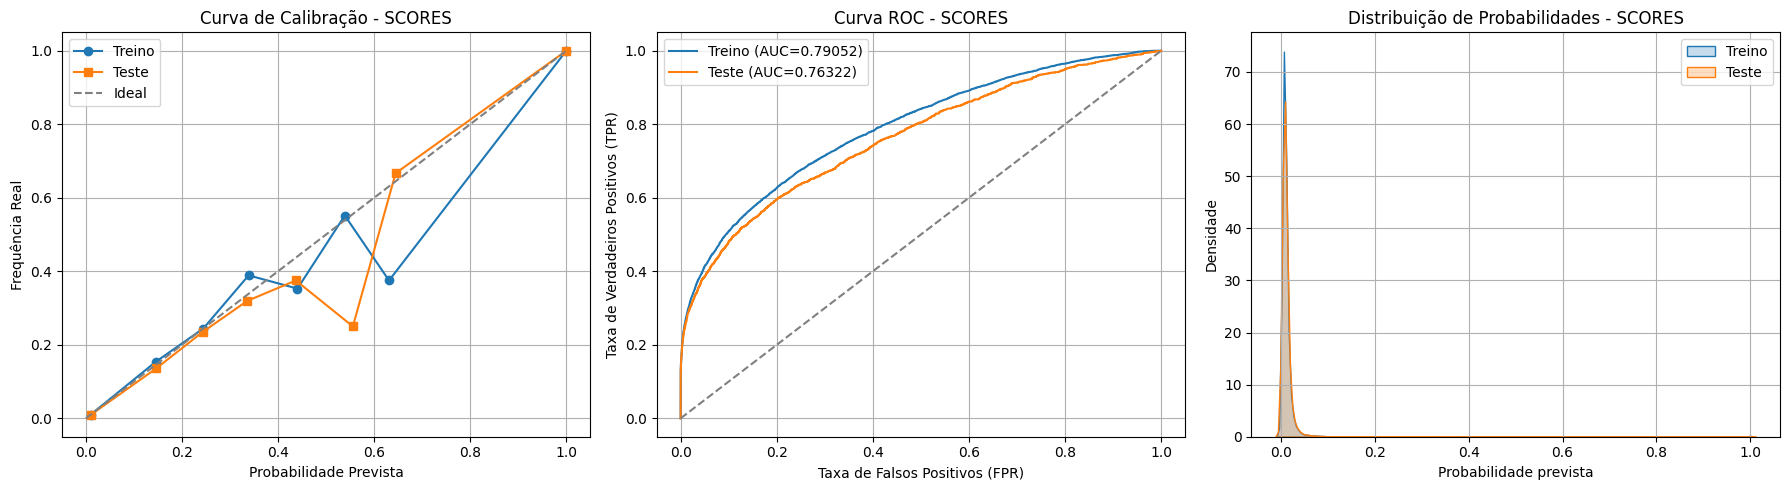

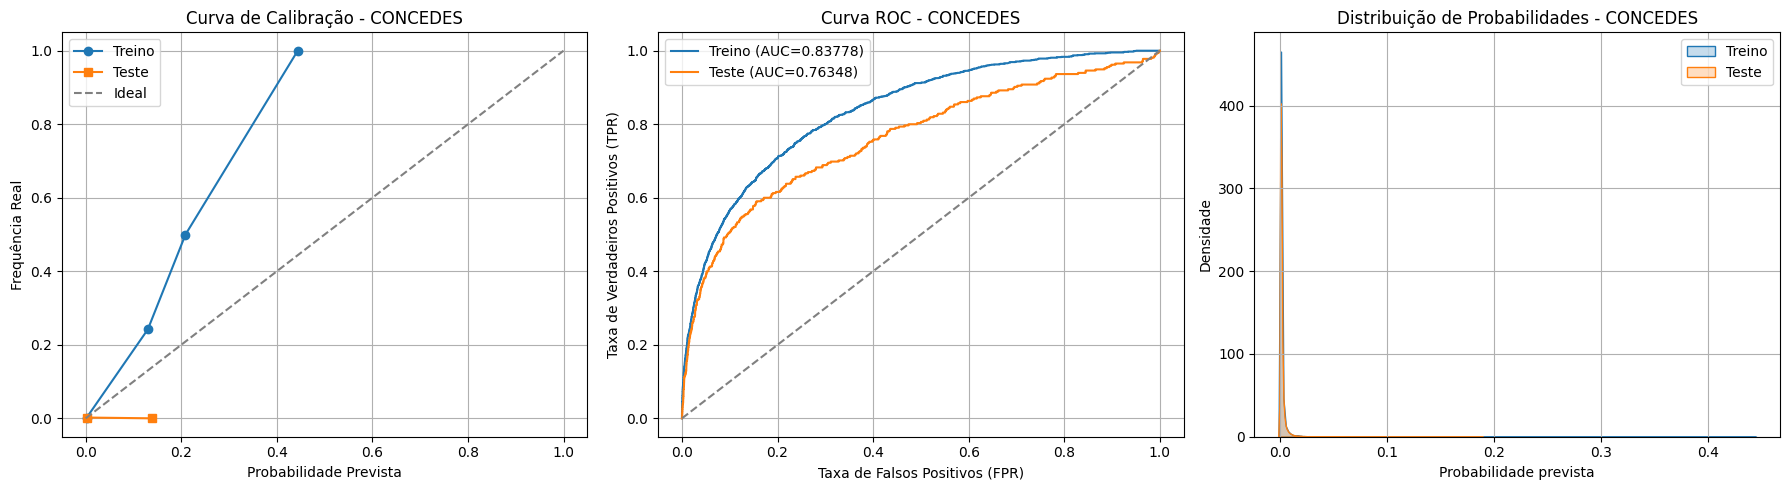

In [45]:
print("\n### GRÁFICOS DE DIAGNÓSTICO PARA OS MODELOS VAEP FINAIS ###\n")

for col in ['scores', 'concedes']:
    plot_model_diagnostics(
        y_train[col], 
        y_test[col], 
        Y_hat_train_final[col], 
        Y_hat_test_final[col], 
        label=col.upper()
    )